# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## Resolución

**Alumno:** Facundo Tomás Cassano Nieto (legajo 65555)

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [1]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cpu | torch 2.14.1+cu130


No cambié ninguna de las constantes de esta sección. Todo se ejecutó en CPU con 2 hilos, así que los tiempos que aparecen en el notebook corresponden a esa máquina.

## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [2]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases


Carga de imágenes: 4s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


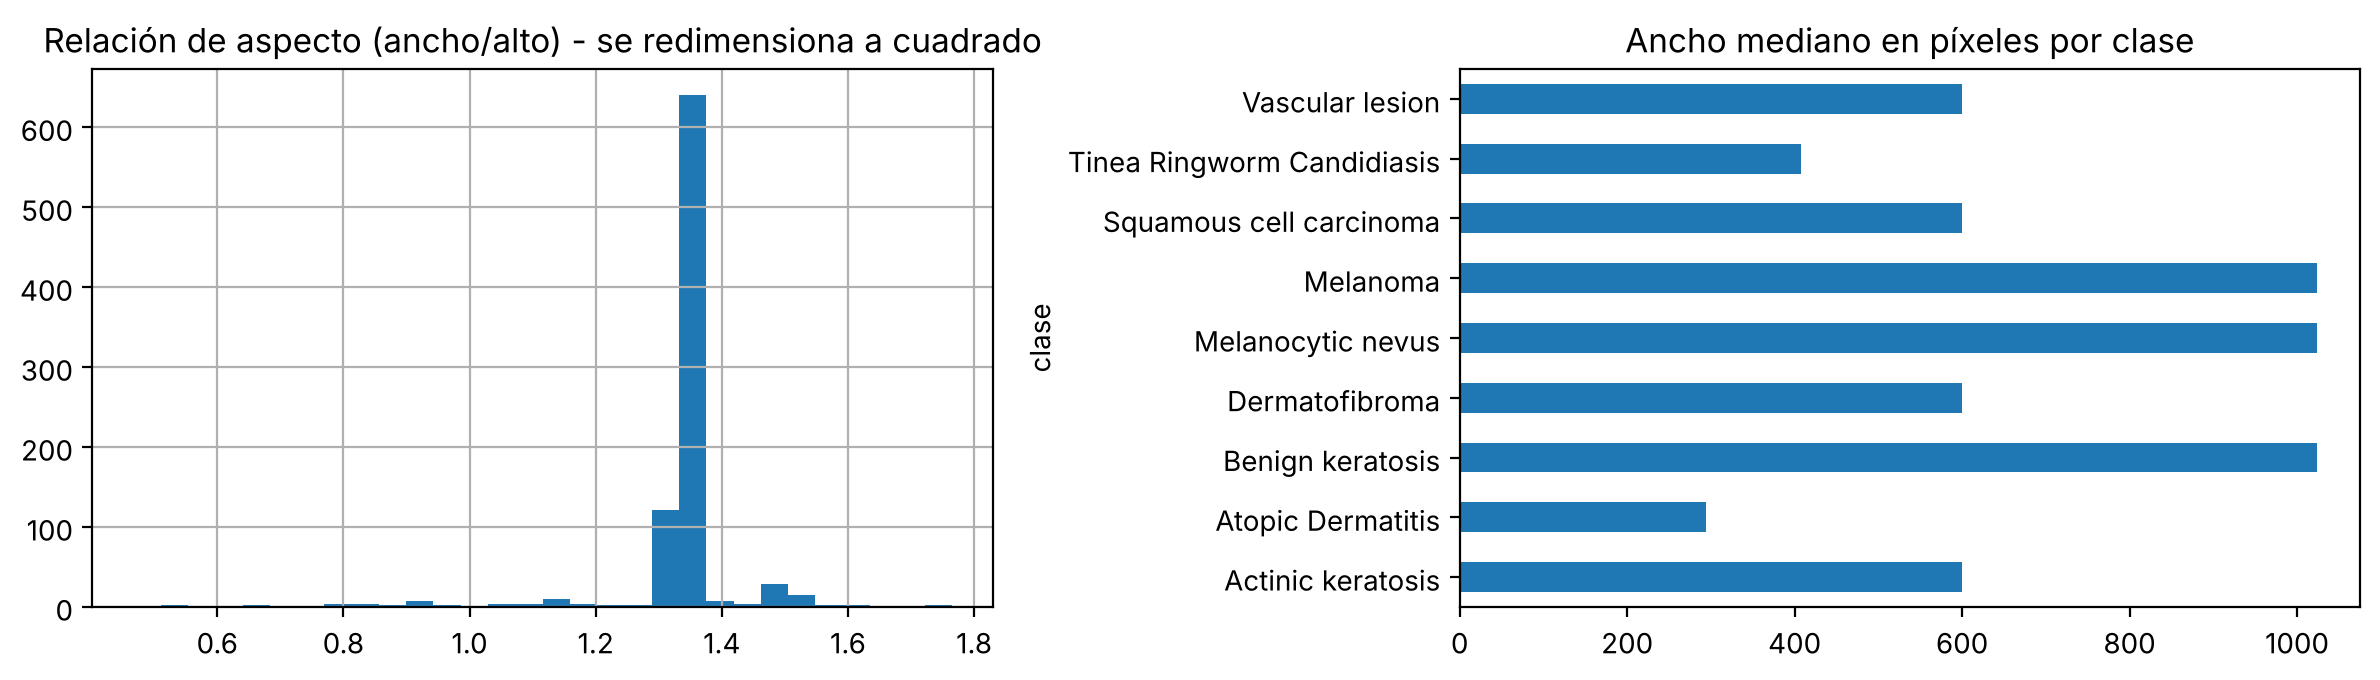

In [3]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

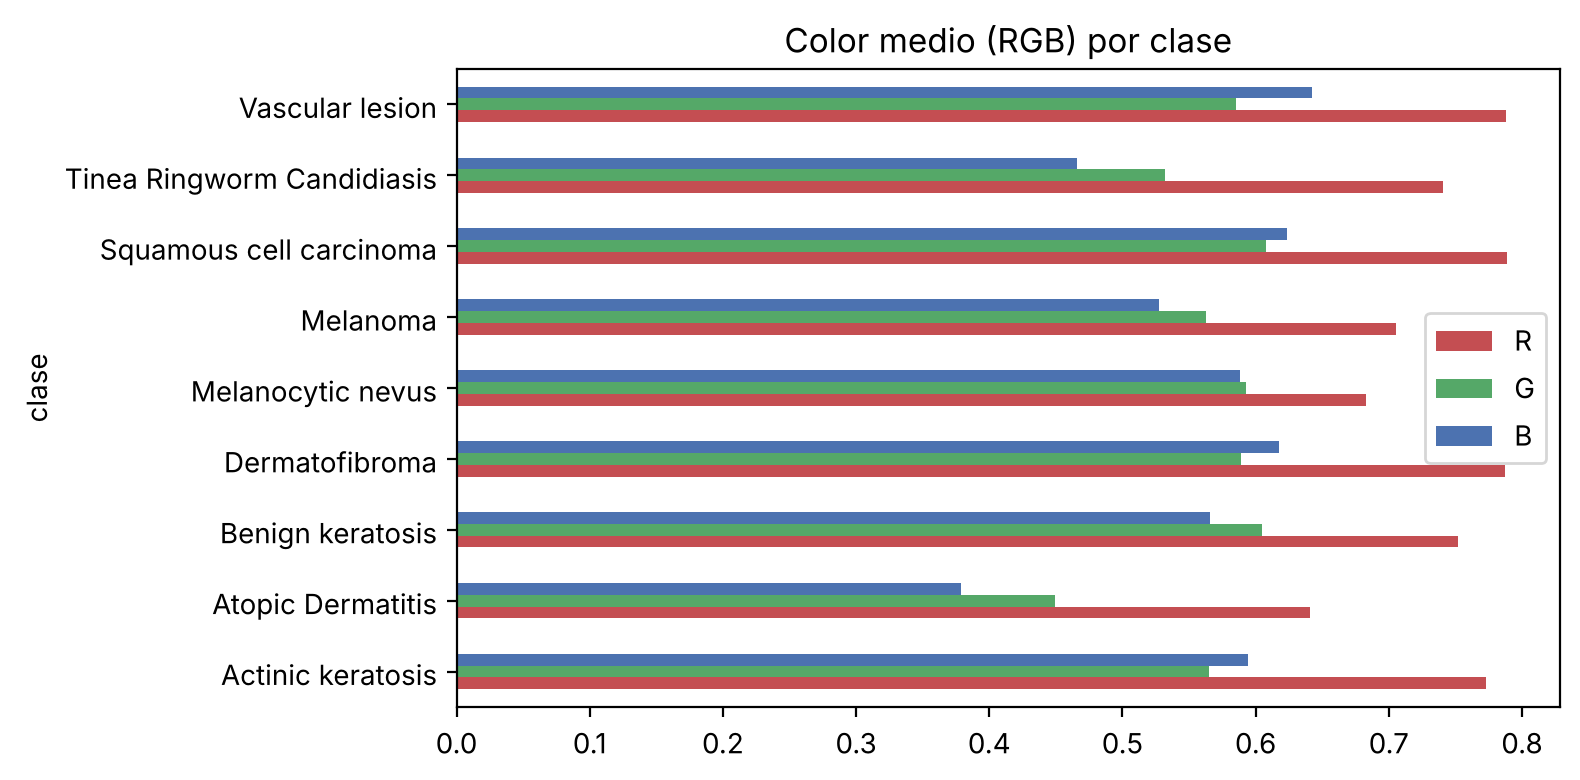

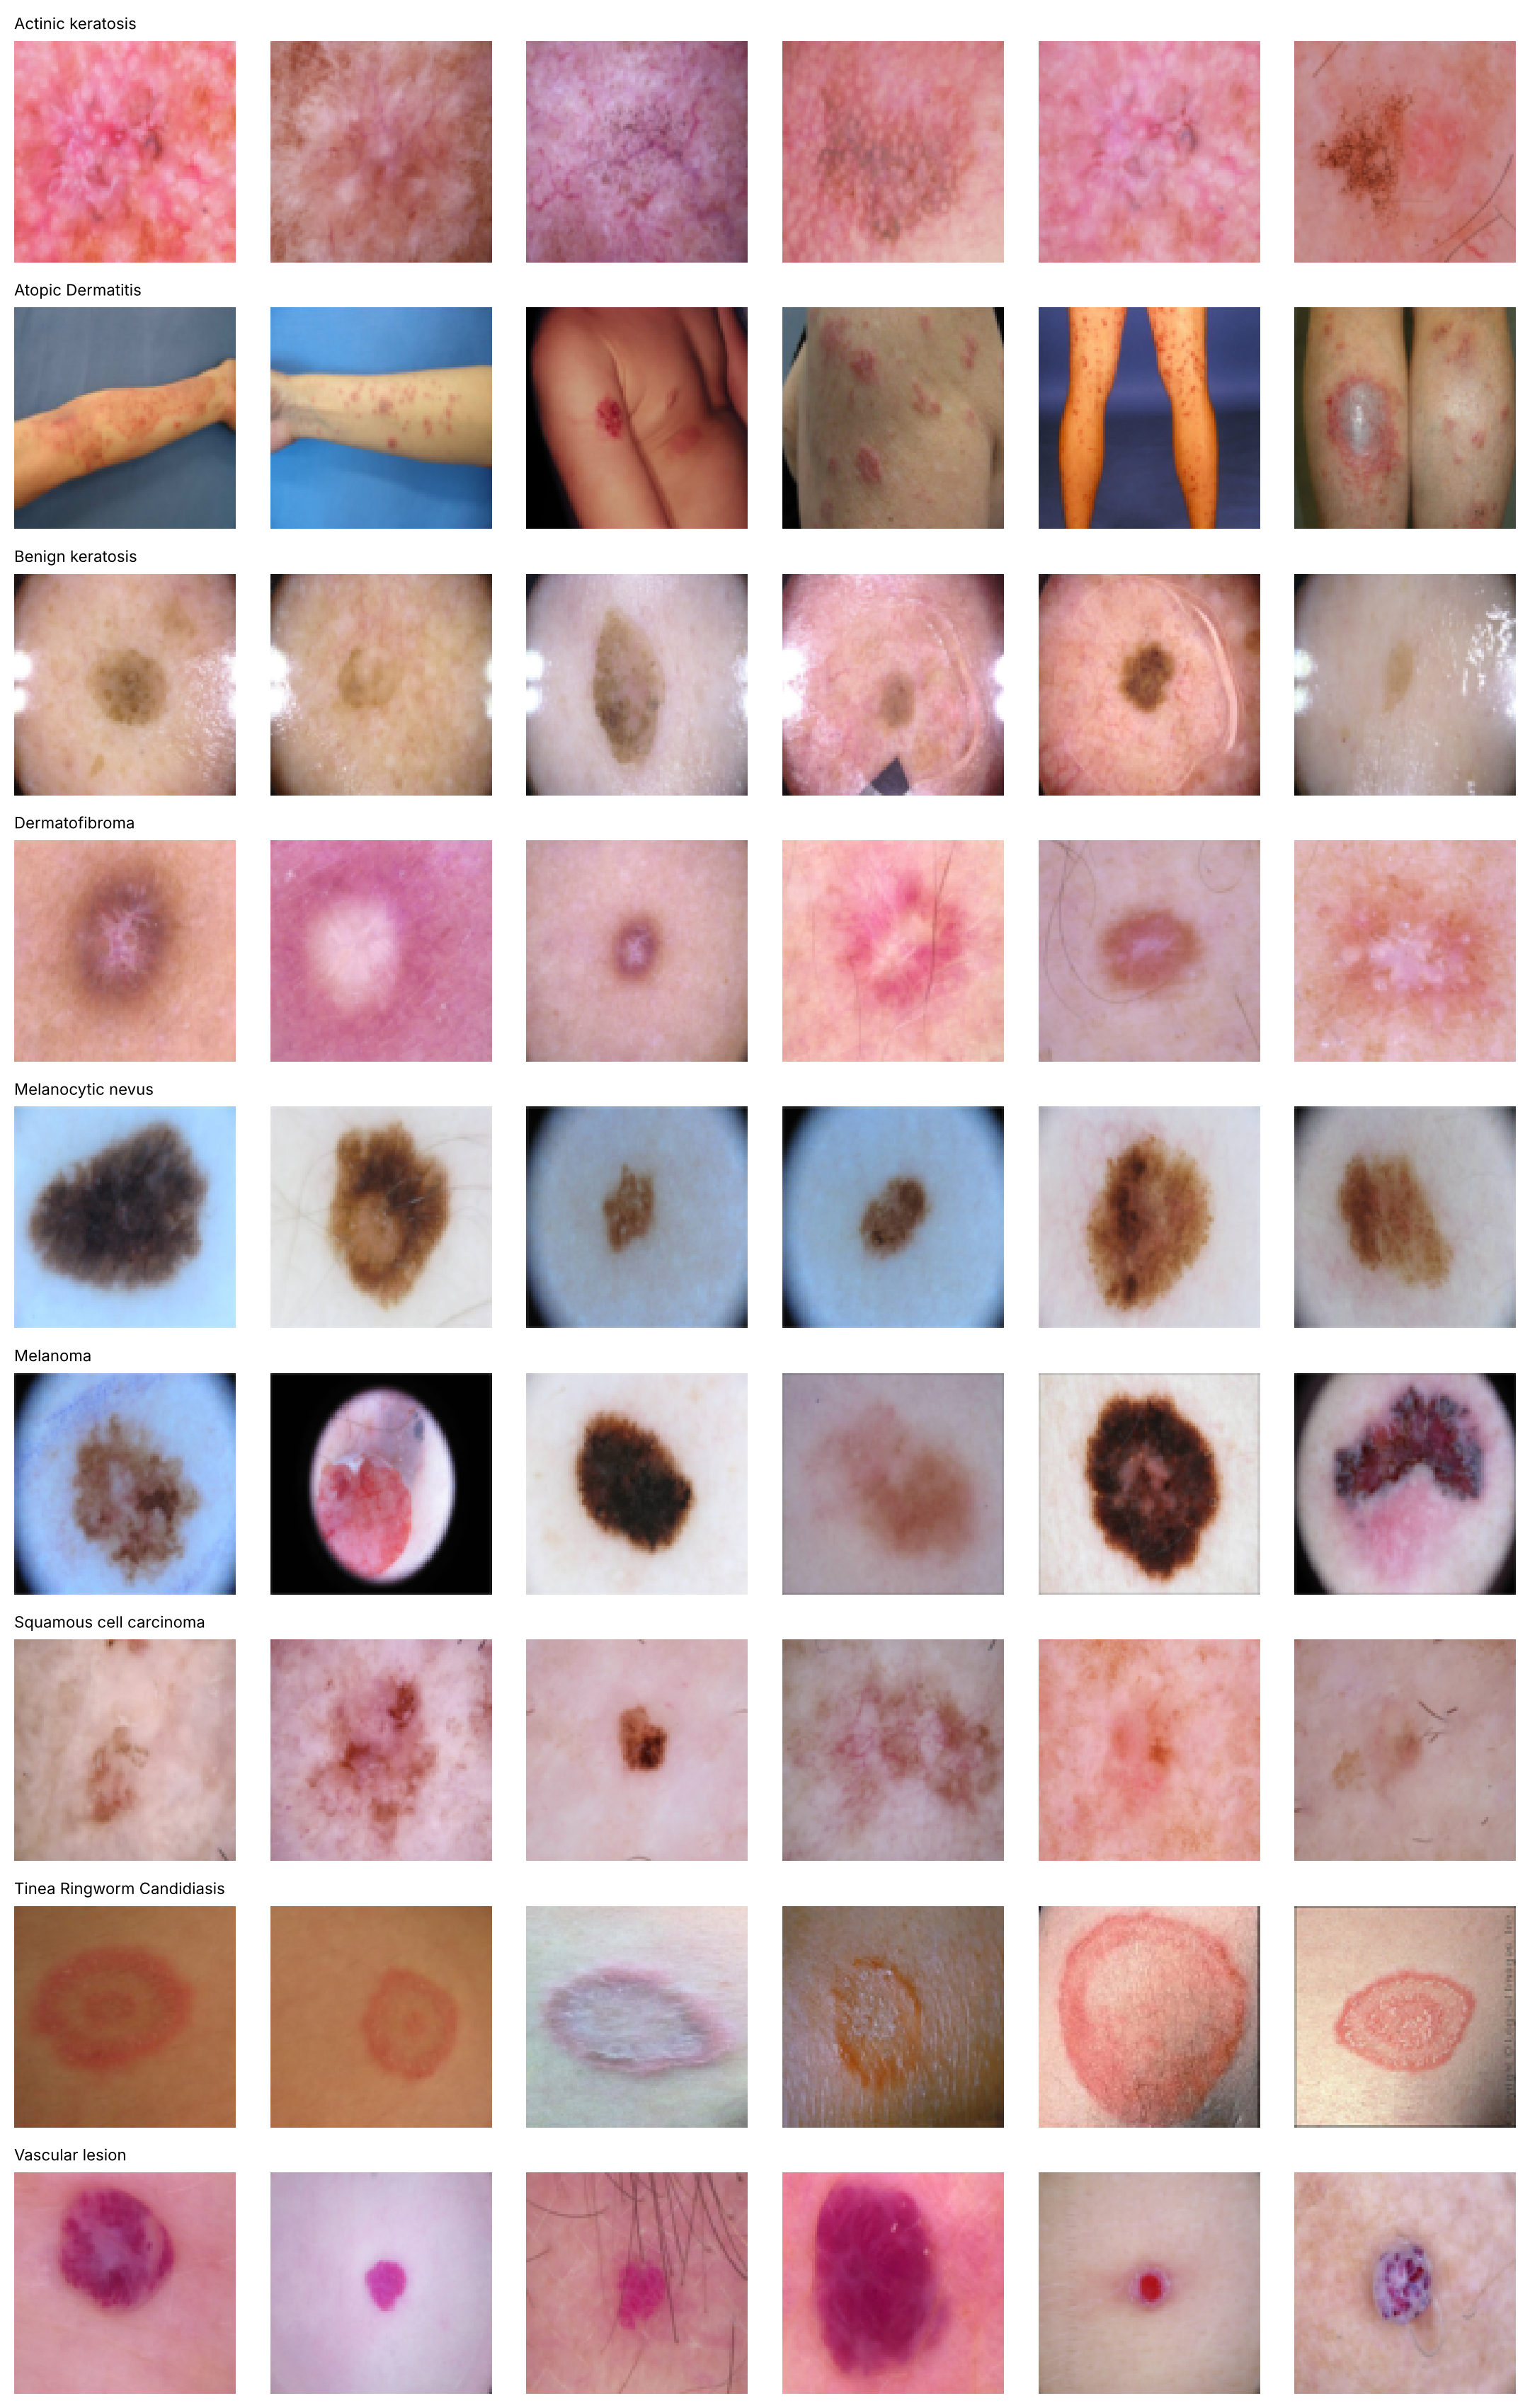

In [4]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [5]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?

---

**Respuestas**

**1.** El desbalance es chico. En las carpetas originales casi todas las clases tienen 100 imágenes (Atopic Dermatitis 102) y la única más chica es Tinea Ringworm Candidiasis, con 76. Pero los duplicados están todos en esas dos clases, así que al sacarlos Atopic Dermatitis baja a 80 y Tinea a 64, y en el split nuevo quedan 48 y 38 imágenes de train contra 60 del resto (Tinea tiene un 37 % menos). Respecto de la partición original cambian tres cosas. La original era 697/181 y no tenía test, la validación tenía 20 imágenes por clase de las cuales 33 en total eran copias exactas de imágenes de train, y ahora el split es 60/20/20 estratificado (506/169/169) sin imágenes repetidas entre conjuntos.

**2.** Sí, y mucho. La resolución casi identifica la clase. Todas las Atopic Dermatitis son de 294×222, todas las Actinic keratosis, Dermatofibroma, Squamous cell carcinoma y Vascular lesion son de 600×450, el 74 % de las Benign keratosis son de 1024×764, el 79 % de los Melanocytic nevus y el 56 % de los Melanoma son de 1024×768, y las Tinea tienen todas resoluciones que no están entre las más comunes. La relación de aspecto es casi siempre de 4 a 3 (entre 1,33 y 1,35), así que al pasar a cuadrado todas se aplastan parecido, salvo un grupo chico con aspecto cercano a 1,5 o menor a 1. En color, Atopic Dermatitis es la más oscura y la menos azul (R 0,64, G 0,45, B 0,38) y Tinea también tiene poco azul. En los ejemplos se ve por qué. Atopic Dermatitis y Tinea son fotos clínicas (brazos, piernas, fondos azules o negros) y no dermatoscopías, las Benign keratosis tienen reflejos blancos del flash sobre el borde izquierdo, y los nevus y melanomas tienen el círculo oscuro del dermatoscopio con fondo celeste.

El riesgo es que el modelo aprenda a reconocer el equipo con el que se sacó la foto en lugar de la lesión. Al redimensionar, una imagen de 1024 px y una de 294 px quedan con distinto nivel de detalle y de borroneo, y el fondo, el viñeteado o los reflejos son pistas fáciles que dentro de este dataset separan clases pero no tienen nada que ver con el diagnóstico. Un modelo así puede tener buen accuracy acá y fallar con fotos de otro equipo.

**3.** Hay 34 grupos de imágenes idénticas por MD5, 33 de ellos repetidos entre `train/` y `val/`, 22 en Atopic Dermatitis y 12 en Tinea, sin conflictos de etiqueta. El hash perceptual encontró 34 pares parecidos y todos son esos mismos duplicados exactos, así que no aparecen casi-duplicados aparte. Importan porque una imagen que está en train y en validación ya fue vista por el modelo, y la validación pasa a medir memoria en lugar de generalización. En Atopic Dermatitis prácticamente todas las imágenes de la validación original (21) eran copias de train, y en Tinea más de la mitad. En total eran 33 de las 181 imágenes de validación (18 %). Si no se eliminaran, esas imágenes se acertarían casi siempre y la val_acc quedaría inflada. Por ejemplo, con un accuracy real de 0,64, la medida sería de alrededor de 0,82 · 0,64 + 0,18 · 1 ≈ 0,70, unos 6 puntos más, y además concentrados en dos clases, que haría parecer que esas clases son fáciles.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [6]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20


mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

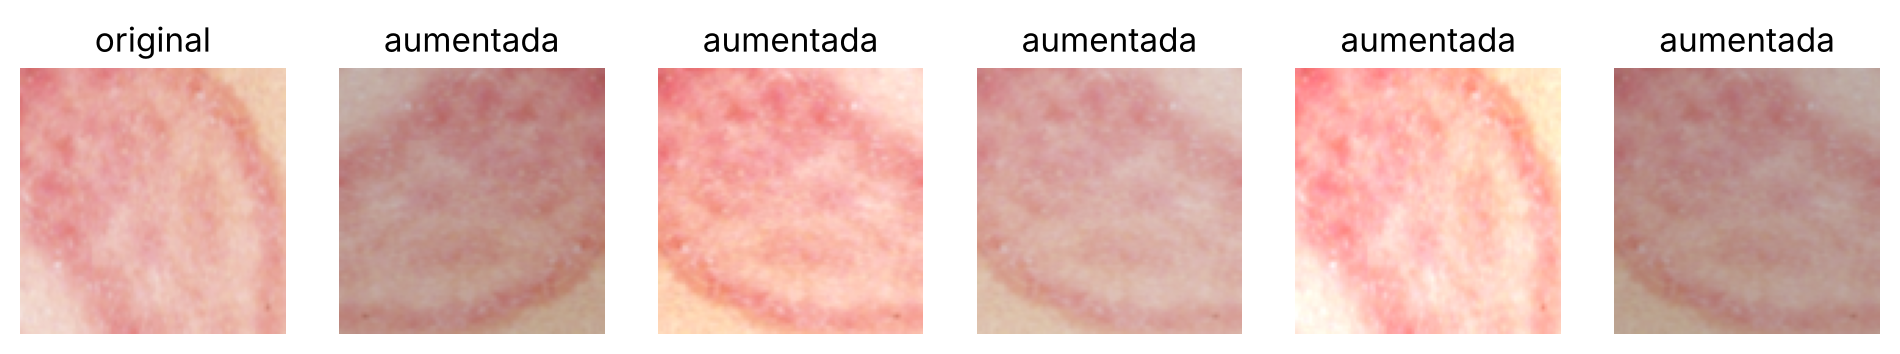

In [7]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [8]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [9]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.

---

**Respuestas**

**1. `padding=kernel // 2`.** Con kernel 3 el padding es 1, y una convolución con stride 1 da un lado de salida de H + 2·p − k + 1 = 64 + 2 − 3 + 1 = 64, o sea que la convolución no cambia el alto ni el ancho y lo único que achica la imagen es el pooling. En la tabla se ve en las tres `Conv2d`, que dan (16, 64, 64), (32, 32, 32) y (64, 16, 16), con el mismo lado que tenían a la entrada. Con `padding=0` cada convolución le sacaría 2 píxeles al lado (k − 1) y con los pooling quedaría 64 → 62 → 31 → 29 → 14 → 12 → 6. El mapa final sería de 6×6 en lugar de 8×8, la `Linear` tendría que recibir 64·6·6 = 2.304 entradas en lugar de 4.096, y como el código calcula `fs = size // 2 ** n_blocks` = 8, la red daría error de dimensiones. Además, sin padding los píxeles del borde participan de menos convoluciones que los del centro.

**2. `MaxPool2d(2)`.** Toma ventanas de 2×2 sin superponer (stride 2) y se queda con el máximo de cada una, en cada canal por separado. Divide el alto y el ancho por 2 y no cambia la cantidad de canales (en la tabla 64 → 32, 32 → 16 y 16 → 8), y no tiene parámetros. Conserva si un filtro se activó fuerte en algún lugar de la ventana y pierde la posición exacta dentro de ella, que es lo que da algo de tolerancia a traslaciones chicas. Como cada bloque divide el lado por 2, después de `n_blocks` bloques el lado es `size // 2 ** n_blocks`, que con 64 px y 3 bloques da 8. Eso es lo que usa el código para saber cuántas entradas tiene la `Linear` (64 canales · 8 · 8 = 4.096).

**3. Parámetros.** La segunda `Conv2d` tiene 32 filtros de 16 canales por 3×3 y no tiene sesgo porque `use_bn=True`, así que son 32 · 16 · 3 · 3 = 4.608 parámetros, igual que en la tabla. La primera `Linear` de la cabeza conecta las 4.096 salidas del `Flatten` con 128 neuronas, con sesgo, así que son 4.096 · 128 + 128 = 524.416. Esa capa sola es el 95 % de los 549.273 parámetros de la red, mientras que las tres convoluciones juntas tienen 23.472 pesos (más 224 de BatchNorm). Domina porque conecta cada posición de cada canal con cada neurona sin compartir nada, mientras que una convolución usa el mismo filtro de 3×3 en todas las posiciones, así que su cantidad de parámetros no depende del tamaño de la imagen.

**4. `bias=not use_bn`.** BatchNorm le resta a cada canal su media en el batch. Un sesgo b de la convolución se suma igual en todas las posiciones y en todas las imágenes del canal, así que también aumenta la media en b y se cancela en la resta. Ese parámetro no tendría ningún efecto en la salida y su gradiente sería 0. El que cumple el papel de sesgo es el β de BatchNorm, que se suma después de normalizar.

**5. `filters * 2 ** b`.** Cada bloque divide la cantidad de posiciones por 4 (mitad de alto y mitad de ancho), y duplicar los canales mantiene parecido el costo de cada bloque. El costo de una convolución es proporcional a alto · ancho · canales de entrada · canales de salida · k², y del bloque 2 al 3 el alto por el ancho baja 4 veces mientras que los canales de entrada por los de salida suben 4 veces (32·32·16·32 = 16·16·32·64). También hace que el tamaño del mapa de activación baje de a poco (16·64·64 = 65.536 valores, después 32.768 y después 16.384) en lugar de caer a la cuarta parte en cada bloque. La idea es que en las primeras capas hay pocos patrones simples (bordes, colores) en muchas posiciones, y en las siguientes se combinan en más tipos de patrones, más complejos, que ya no necesitan tanta resolución espacial.

**6. Campo receptivo.** `rf_full` arranca con r = 1 y un salto j = 1. Cada convolución suma (k − 1)·j y cada pooling suma 1·j y duplica el salto. En el bloque 1 la convolución deja r = 1 + 2·1 = 3 y el pooling r = 3 + 1 = 4 con j = 2. En el bloque 2 la convolución deja r = 4 + 2·2 = 8 y el pooling r = 8 + 2 = 10 con j = 4. En el bloque 3 la convolución deja r = 10 + 2·4 = 18, y el último pooling no se cuenta porque se mide en la última convolución. Significa que cada unidad de la última convolución depende de una ventana de 18×18 píxeles de la entrada, que es el 28 % del lado de una imagen de 64 px y menos del 8 % de su área. Ninguna neurona convolucional ve la lesión completa, lo que pueden detectar son bordes y texturas locales. La forma global (asimetría, contorno completo) solo se puede combinar en la `Linear` de la cabeza, que recibe todas las posiciones.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 7 | val_acc 0.609 | train_acc 0.686 | 0.56 s/época | total 18s


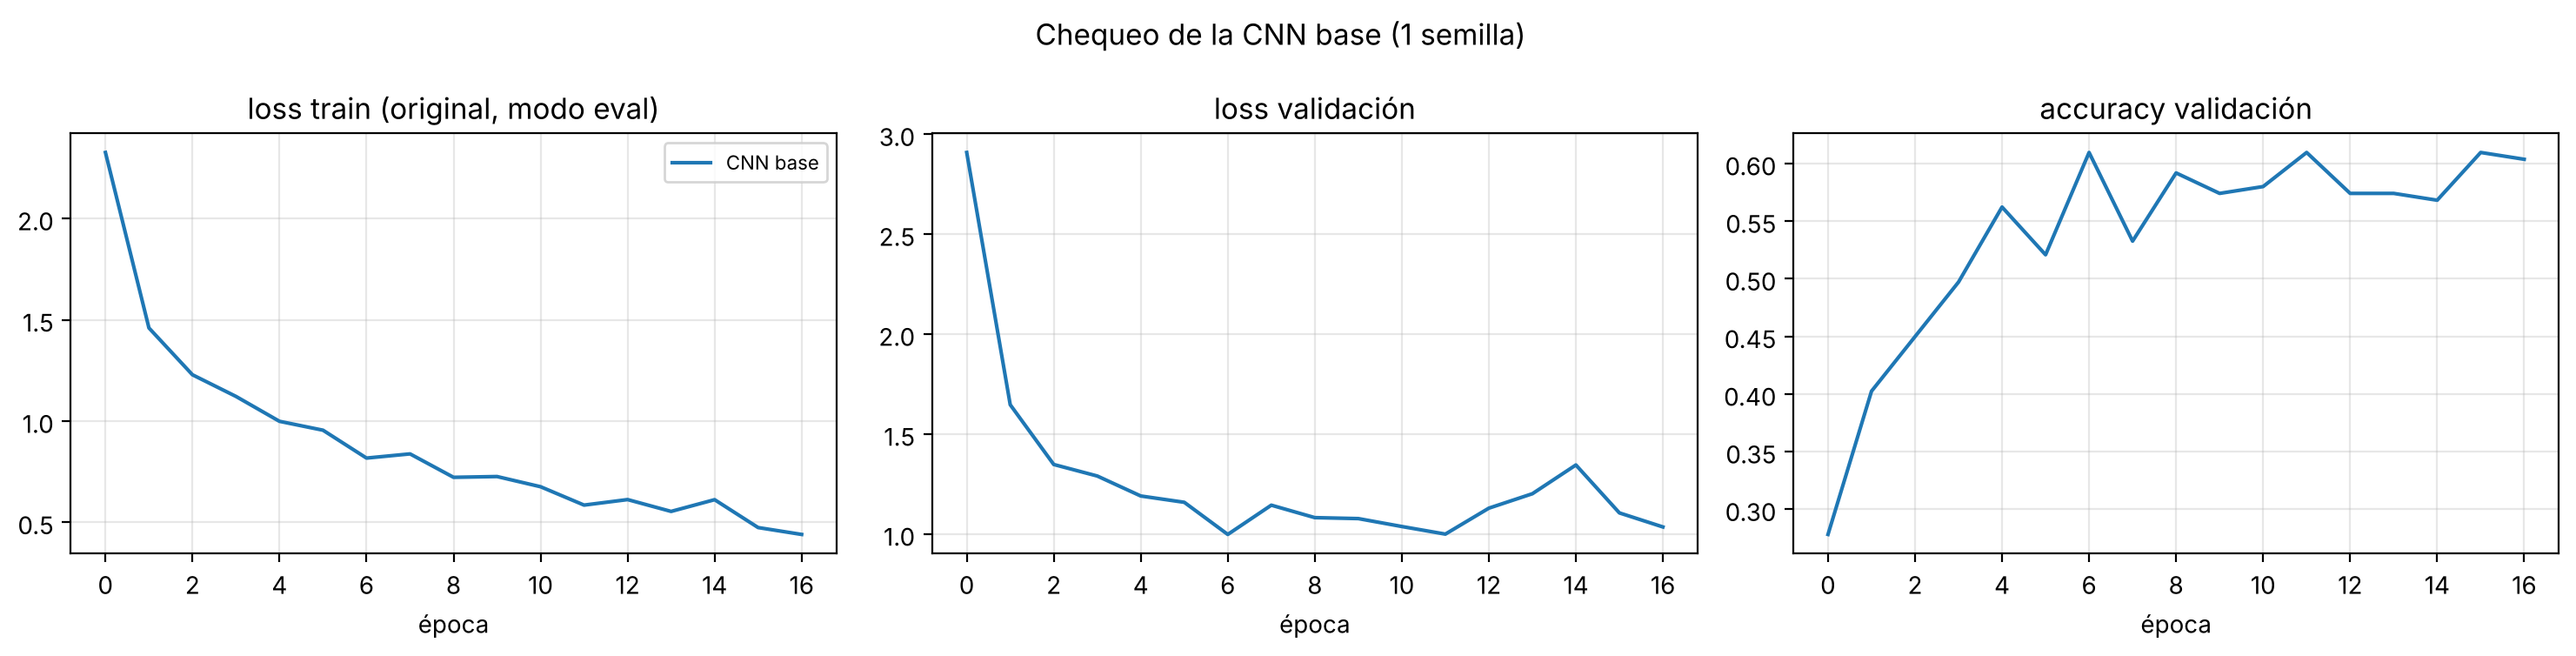

In [10]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4951,0.0388,0.7358,0.2408,5.0000,0.0856,0.4366,0.0585
1,MLP 64px,6358793,0.5365,0.0356,0.6950,0.1585,6.3333,0.2901,0.4352,0.1012
2,CNN 32px,156057,0.6607,0.0148,0.8630,0.2022,10.3333,0.1750,0.6049,0.0559
3,CNN 64px,549273,0.6391,0.0269,0.8017,0.1627,12.3333,0.5684,0.5654,0.0736


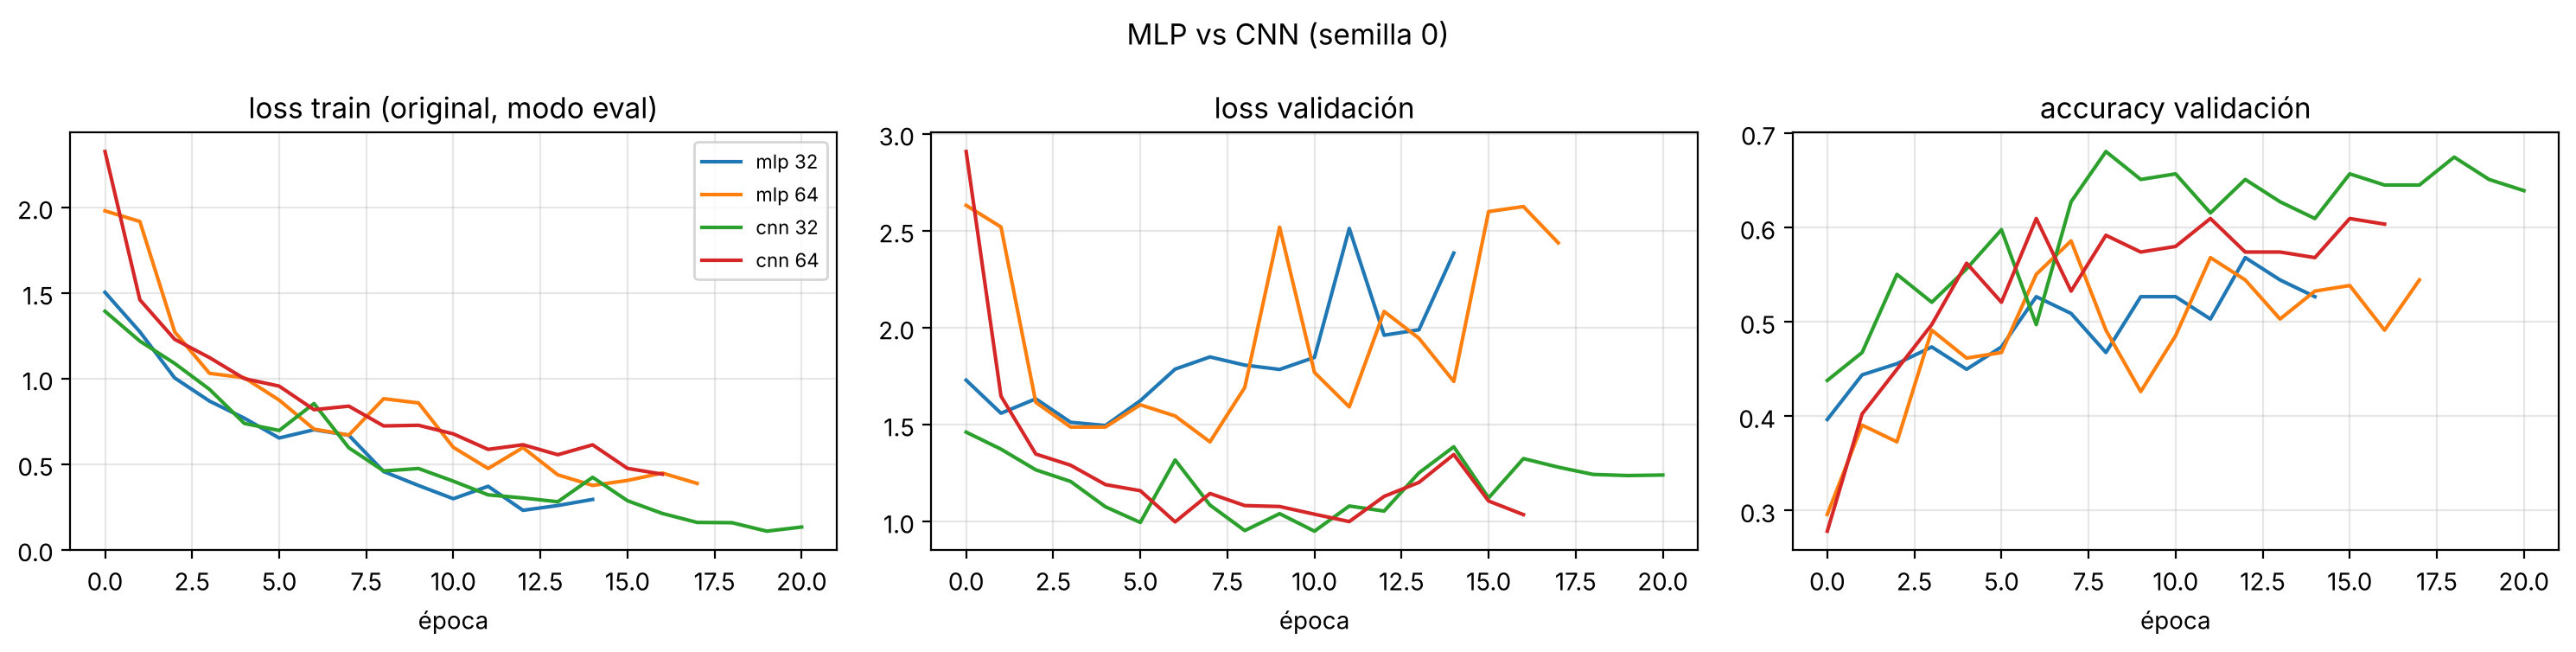

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [11]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?

---

**Respuestas**

**1.** A 64 px la CNN tiene 549.273 parámetros contra 6.358.793 de la MLP (11 veces menos) y llega a 0,639 ± 0,027 de val_acc contra 0,537 ± 0,036, unos 10 puntos más. A 32 px la diferencia es mayor, 0,661 ± 0,015 contra 0,495 ± 0,039 (17 puntos), con 156.057 parámetros contra 1.640.201. La diferencia supera el ruido entre semillas (desvíos de 1,5 a 3,9 puntos) y el error estándar de la validación (unos 3,7 puntos con 169 imágenes), aunque a 64 px es de menos de 3 errores estándar, así que es clara pero no enorme. La brecha train-val es parecida (16 puntos las dos a 64 px, y 20 a 24 a 32 px), pero la MLP también ajusta peor el train (0,70 contra 0,80 a 64 px), o sea que no solo generaliza peor sino que le cuesta aprender. La CNN converge más tarde (mejor época 10 a 12 contra 5 a 6) y en las curvas la loss de validación de la MLP sube y salta mucho después de la época 5, mientras que la de la CNN se mantiene. En tiempo por época la CNN es más lenta aunque tenga menos parámetros (0,57 s contra 0,29 s a 64 px y 0,18 s contra 0,086 s a 32 px), porque cada filtro se aplica en todas las posiciones de la imagen y el cálculo depende de los parámetros por la cantidad de posiciones.

**2.** La primera capa de la MLP conecta cada píxel de cada canal con cada una de las 512 neuronas. A 32 px son 3 · 32 · 32 = 3.072 entradas, así que tiene 3.072 · 512 + 512 = 1.573.376 parámetros (el 96 % de la MLP). A 64 px son 12.288 entradas y 12.288 · 512 + 512 = 6.291.968 parámetros (el 99 %). A 224 px serían 3 · 224 · 224 = 150.528 entradas y 150.528 · 512 + 512 = 77.070.848 parámetros solo en la primera capa, unas 150.000 por cada imagen de train. La convolución cambia ese número por dos propiedades. La conectividad local hace que cada salida dependa solo de una ventana de k × k × canales (27 pesos en la primera capa, en lugar de 12.288), y los pesos compartidos hacen que el mismo filtro se use en todas las posiciones. Por eso la cantidad de parámetros de las convoluciones no depende del tamaño de la imagen, y lo único que crece con la resolución es la `Linear` de la cabeza.

**3.** Con traslaciones de hasta ±4 px a 32 px y ±8 px a 64 px, la MLP pierde 5,9 y 10,1 puntos y la CNN 5,6 y 7,4. A 64 px la CNN se degrada menos (pierde el 12 % de su accuracy contra el 19 % de la MLP) y a 32 px las dos pierden casi lo mismo. Es coherente con la teoría. La convolución es equivariante (si la imagen se mueve, el mapa de activación se mueve igual) y el pooling da algo de invariancia, mientras que en la MLP cada píxel tiene sus propios pesos y una traslación cambia por completo la entrada. Pero la CNN tampoco es invariante del todo, porque la `Linear` de la cabeza tiene pesos distintos para cada posición del mapa final, y con 3 poolings de 2 la tolerancia es de unos pocos píxeles. Además la traslación es circular y deja una costura en la imagen, que es un artefacto para los dos modelos. Igual la diferencia entre las caídas (2,7 puntos a 64 px) es menor que el error estándar de la validación, así que el ruido no permite concluirlo con seguridad.

**4.** La media y el desvío de cada canal se calculan solo con las imágenes de train y en cada resolución (a 64 px, media [0,743 0,572 0,565] y desvío [0,162 0,164 0,186]), y se usan para normalizar train, validación y test. Calcularlas con todas las imágenes filtraría información de validación y test. La normalización deja cada canal centrado en 0 y con desvío 1, que es la escala para la que está pensada la inicialización de PyTorch, y evita que todas las entradas sean positivas (los píxeles van de 0 a 1). Si todas las entradas de una neurona son positivas, los gradientes de todos sus pesos tienen el mismo signo y el descenso va en zigzag. Sin normalizar esperaría un entrenamiento más lento e inestable, sobre todo en la MLP. La CNN depende menos, porque tiene BatchNorm después de cada convolución y solo la primera convolución vería la escala original.

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6391,0.0269,0.8017,0.1627,12.3333,0.5752,12.8326
1,2 bloques,8,1055001,0.5976,0.0242,0.7628,0.1652,10.0000,0.4646,9.2881
2,4 bloques,38,361113,0.6469,0.0201,0.8314,0.1844,16.3333,0.6777,17.8423
3,kernel 5,32,591001,0.5937,0.0391,0.7484,0.1547,14.6667,0.8357,20.7106
4,kernel 7,46,653593,0.6134,0.0223,0.7563,0.1428,15.0000,1.2312,30.7575
5,8 filtros,18,269521,0.6331,0.0211,0.7714,0.1383,7.0000,0.3386,5.7564
6,32 filtros,18,1143337,0.5976,0.0348,0.7530,0.1553,13.3333,1.4968,35.0011
7,32 px,18,156057,0.6607,0.0148,0.8630,0.2022,10.3333,0.1961,3.9800
8,96 px,18,1204633,0.6016,0.0056,0.7543,0.1527,12.3333,1.3597,30.3812


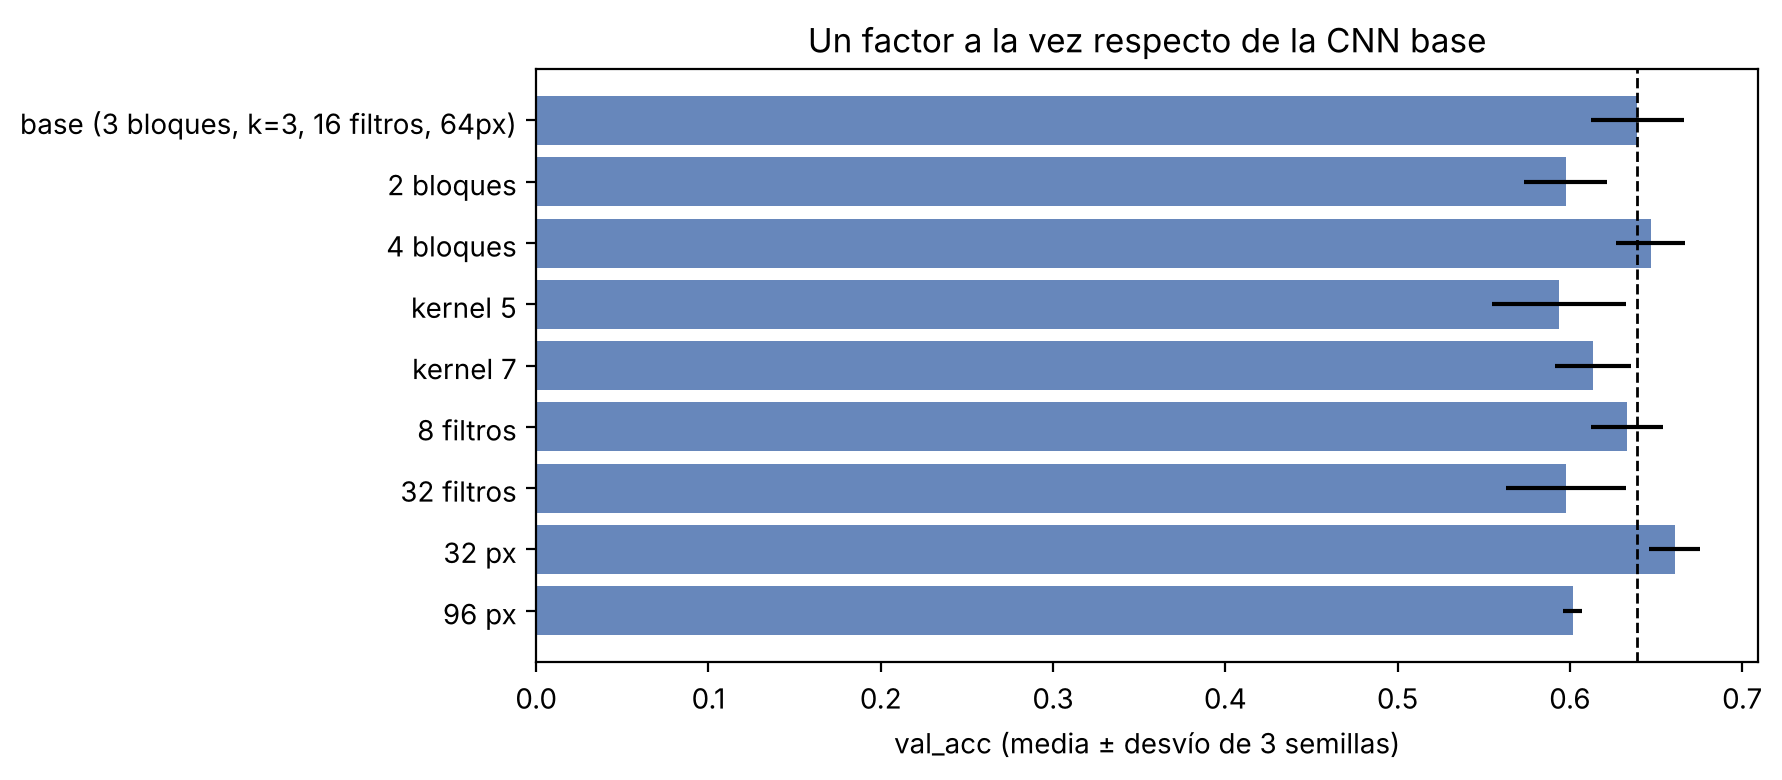

In [12]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?

---

**Respuestas**

**1.** Ninguno con seguridad. Todas las variantes quedan entre 0,594 y 0,661, y los desvíos entre semillas van de 0,6 a 3,9 puntos (y están calculados con 3 semillas y `np.std` sin corrección, así que subestiman el ruido real). Además el error estándar de una val_acc de 0,64 con 169 imágenes es de unos 3,7 puntos. Respecto de la base (0,639), 4 bloques (+0,8) y 8 filtros (−0,6) son diferencias chicas comparadas con el ruido, y 32 px (+2,2) también. Las que quedan más abajo son 2 bloques (−4,2), kernel 5 (−4,5), 32 filtros (−4,2), 96 px (−3,8) y kernel 7 (−2,6). Son del orden de 1 desvío o 1 error estándar, así que a lo sumo muestran una tendencia de que las variantes más grandes o más caras no andan mejor, pero no una diferencia real.

**2.** El campo receptivo pasa de 8 px con 2 bloques a 18 con la base, 38 con 4 bloques, 32 con kernel 5 y 46 con kernel 7. En estas imágenes la lesión suele ocupar buena parte del cuadro, así que para la forma global y la asimetría haría falta un campo receptivo grande, mientras que las texturas (puntos, red de pigmento) son locales. Esperaba que agregar bloques o agrandar el kernel ayudara. Con 4 bloques la val_acc sube un poco (0,647, dentro del ruido), con menos parámetros que la base (361.113, porque el mapa final es de 4×4 y la `Linear` recibe 2.048 entradas en lugar de 4.096), pero cada época tarda más (0,68 s contra 0,58 s) y necesita más épocas (16,3 contra 12,3). Agrandar el kernel no mejoró (0,594 y 0,613) y es lo más caro, porque los pesos de las convoluciones crecen con k² (1,23 s por época con kernel 7). Con 2 bloques el campo receptivo de 8 px es muy local y la `Linear` recibe 32·16·16 = 8.192 entradas, así que la red tiene el doble de parámetros (1.055.001) y anda peor (0,598). En costo contra ganancia, ninguna de las variantes más caras se justifica.

**3.** La `Linear` recibe 64 · (size/8)² entradas. Con 32 px son 1.024 entradas y 131.200 parámetros, con 64 px 4.096 y 524.416, y con 96 px 9.216 y 1.179.776, o sea que crece con el cuadrado de la resolución porque el mapa final escala con el lado de la imagen. Más resolución da más detalle de las estructuras finas de la lesión, pero cuesta más cálculo (0,20, 0,58 y 1,36 s por época), muchos más parámetros para solo 506 imágenes de train, y el campo receptivo fijo de 18 px cubre una parte cada vez más chica de la imagen (56 % del lado a 32 px, 28 % a 64 y 19 % a 96). En los resultados la mejor fue 32 px (0,661) y la peor 96 px (0,602), aunque dentro del ruido. El límite del experimento es que con unas 60 imágenes por clase el modelo no tiene datos para aprovechar el detalle extra, y que al cambiar la resolución sin cambiar la arquitectura también cambia el campo receptivo relativo, así que no se puede separar el efecto del detalle del efecto de ver una parte más chica de la lesión.

**4.** Con un factor a la vez no se ven interacciones. Por ejemplo, 96 px probablemente necesite 4 bloques para que el campo receptivo cubra una parte parecida de la imagen, o un kernel más grande podría andar mejor con menos filtros. Por la misma razón, juntar la mejor variante de cada experimento no garantiza que la combinación sea la mejor. Con 3 semillas sobre el mismo split el desvío es una estimación muy gruesa y no incluye la variación por qué imágenes caen en validación. Y el resto de los hiperparámetros (lr 0,003, dropout, batch) quedó fijo en lo que se eligió para la base, que puede no ser lo mejor para cada variante.

## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6391,0.0269,0.8017,0.1627,1.0374,12.3333,0.6653,14.7399
1,flips,1518,0.6272,0.0174,0.8149,0.1877,1.0300,8.3333,1.9413,35.6689
2,flips+rot90,1518,0.6154,0.0317,0.7556,0.1402,1.0416,7.6667,1.8681,32.9953
3,flips+rot90+color,1518,0.6331,0.0302,0.8195,0.1864,0.9695,10.6667,1.8856,38.9695


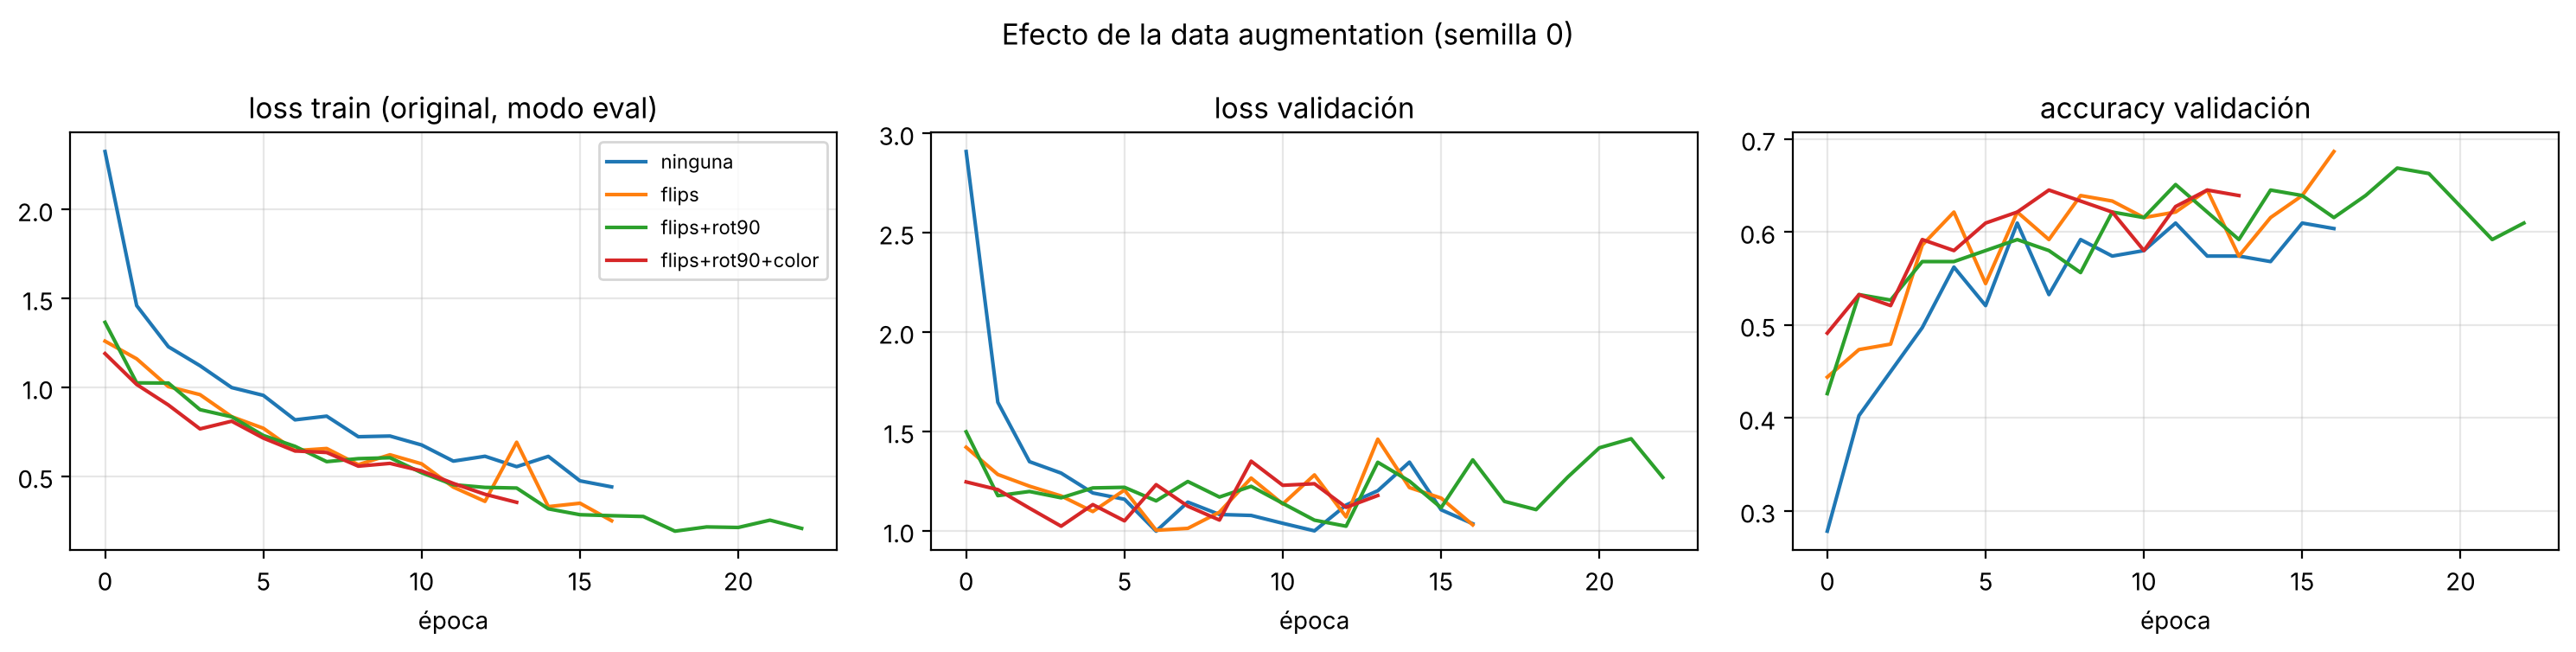

In [13]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?

---

**Respuestas**

**1.** Sin augmentation, en la mejor época la CNN base tiene 0,802 de accuracy en train (medido en modo eval sobre las imágenes originales) contra 0,639 en validación, una brecha de 16 puntos con el promedio de 3 semillas. En la semilla 0 (chequeo de la sección 4.2 y curva "ninguna" de esta sección) la val_loss tiene su mínimo en la época 7, de alrededor de 1,0, y después oscila entre 1,0 y 1,35 sin mejorar mientras la loss de train sigue bajando (de 2,3 a menos de 0,5). El early stopping corta 10 épocas después y restaura el estado de la época 7. A 32 px la brecha es todavía mayor (0,863 contra 0,661, 20 puntos).

**2.** Ningún nivel mejora la val_acc más allá del ruido. Sin augmentation da 0,639 ± 0,027, con flips 0,627 ± 0,017, con flips y rotaciones de 90° 0,615 ± 0,032 y con color además 0,633 ± 0,030. Las diferencias son de 2,4 puntos como mucho, menores que el desvío entre semillas. La brecha tampoco baja de forma consistente. Sube a 18,8 y 18,6 puntos con flips y con color y baja a 14 con rotaciones, pero esa baja viene más de que el train se ajusta peor (0,756) que de que mejore la validación. La val_loss mínima mejora un poco solo con color (0,970 contra 1,037). Con augmentation la mejor época llega antes (7,7 a 10,7 contra 12,3), porque cada época tiene 3 veces más imágenes (1.518 contra 506) y hace 3 veces más pasos. Por lo mismo cada época cuesta unas 3 veces más (1,87 a 1,94 s contra 0,67 s) y el entrenamiento completo entre 2 y 3 veces más (33 a 39 s contra 14,7 s).

Creo que no ayuda por dos motivos. Las copias aumentadas se generan una sola vez, así que la red ve siempre las mismas 3 versiones de cada imagen y no hay variabilidad nueva en cada época como con augmentation en línea. Y si una parte de lo que aprende el modelo son pistas de adquisición (resolución, fondo, viñeteado), girar o espejar la imagen no las elimina.

**3.** En dermatoscopía la lesión no tiene una orientación privilegiada, así que los flips y las rotaciones de 90° no cambian el diagnóstico y tienen sentido. Con el color hay que tener cuidado, porque es información diagnóstica (el velo azul-blanquecino y los tonos negros en melanoma, el rojo y violeta en las lesiones vasculares, el rosado en carcinomas). Cambios chicos de brillo y contraste, como el ±20 % que se usa acá, simulan distinta iluminación o distintos equipos, pero cambios grandes de tono podrían hacer que una lesión parezca de otra clase. La escala también lleva información (el tamaño relativo de la lesión, y en este dataset hasta la resolución) y un recorte o zoom fuerte puede cortar el borde, que es justamente lo que se mira para la asimetría y la irregularidad. Probaría rotaciones de ángulo arbitrario y recortes chicos que no corten la lesión, cambios suaves de tono, desenfoque y ruido (para que la red no dependa del nivel de detalle de cada equipo), y sobre todo augmentation en línea, con transformaciones nuevas en cada época.

**4.** Si se aumentara antes de dividir, las versiones transformadas de una misma imagen podrían quedar unas en train y otras en validación o test, y el modelo se evaluaría sobre imágenes que en la práctica ya vio, el mismo problema que con los duplicados del EDA. Las métricas darían más altas de lo que el modelo generaliza. Validación y test no se aumentan porque tienen que representar las imágenes reales tal como van a llegar. Aumentarlas cambia su distribución y además agrega copias correlacionadas que no son muestras independientes, así que el error estándar calculado con la cantidad de imágenes quedaría mal.

**5.** Dropout y L2 restringen al modelo. L2 penaliza los pesos grandes y dropout obliga a que las neuronas no dependan unas de otras, pero ninguna de las dos agrega información sobre el problema. La augmentation agrega datos sintéticos que codifican algo que sabemos del dominio (que la orientación no importa), y no cambia el modelo. En el TP3, con Adam, la penalización L2 empeoró la val_acc porque llevaba a 0 los pesos de las palabras poco frecuentes, dropout redujo la caída de la val_acc al seguir entrenando y BatchNorm fue lo que mejor anduvo. Acá la CNN ya tiene BatchNorm en cada bloque y dropout en la cabeza. La augmentation cuesta mucho más tiempo por época que una penalización y depende de que las transformaciones no cambien la etiqueta, y en este caso, con copias fijas, no alcanzó para mejorar.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [14]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 32 px | mejor augmentation (val): ninguna
Config final: {'model': 'cnn', 'size': 32, 'n_blocks': 3, 'filters': 16, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'ninguna'}


Config final en validación: val_acc 0.661 ± 0.015 | brecha 0.202 | mejor época 10.3 | 4s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,156057,0.6734,0.0354,0.6708,0.0351,3.8925
1,MLP 64px,6358793,0.5136,0.0527,0.4961,0.0568,5.5163


Error estándar binomial del test (169 imágenes): ±0.036 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.44      0.70      0.54        20
         Atopic Dermatitis       0.89      1.00      0.94        16
          Benign keratosis       0.76      0.95      0.84        20
            Dermatofibroma       0.75      0.30      0.43        20
         Melanocytic nevus       0.72      0.90      0.80        20
                  Melanoma       0.78      0.35      0.48        20
   Squamous cell carcinoma       0.55      0.60      0.57        20
Tinea Ringworm Candidiasis       0.89      0.62      0.73        13
           Vascular lesion       0.81      0.85      0.83        20

                  accuracy                           0.69       169
                 macro avg       0.73      0.70      0.68       169
              weighted avg       0.72      0.69      0.68       169



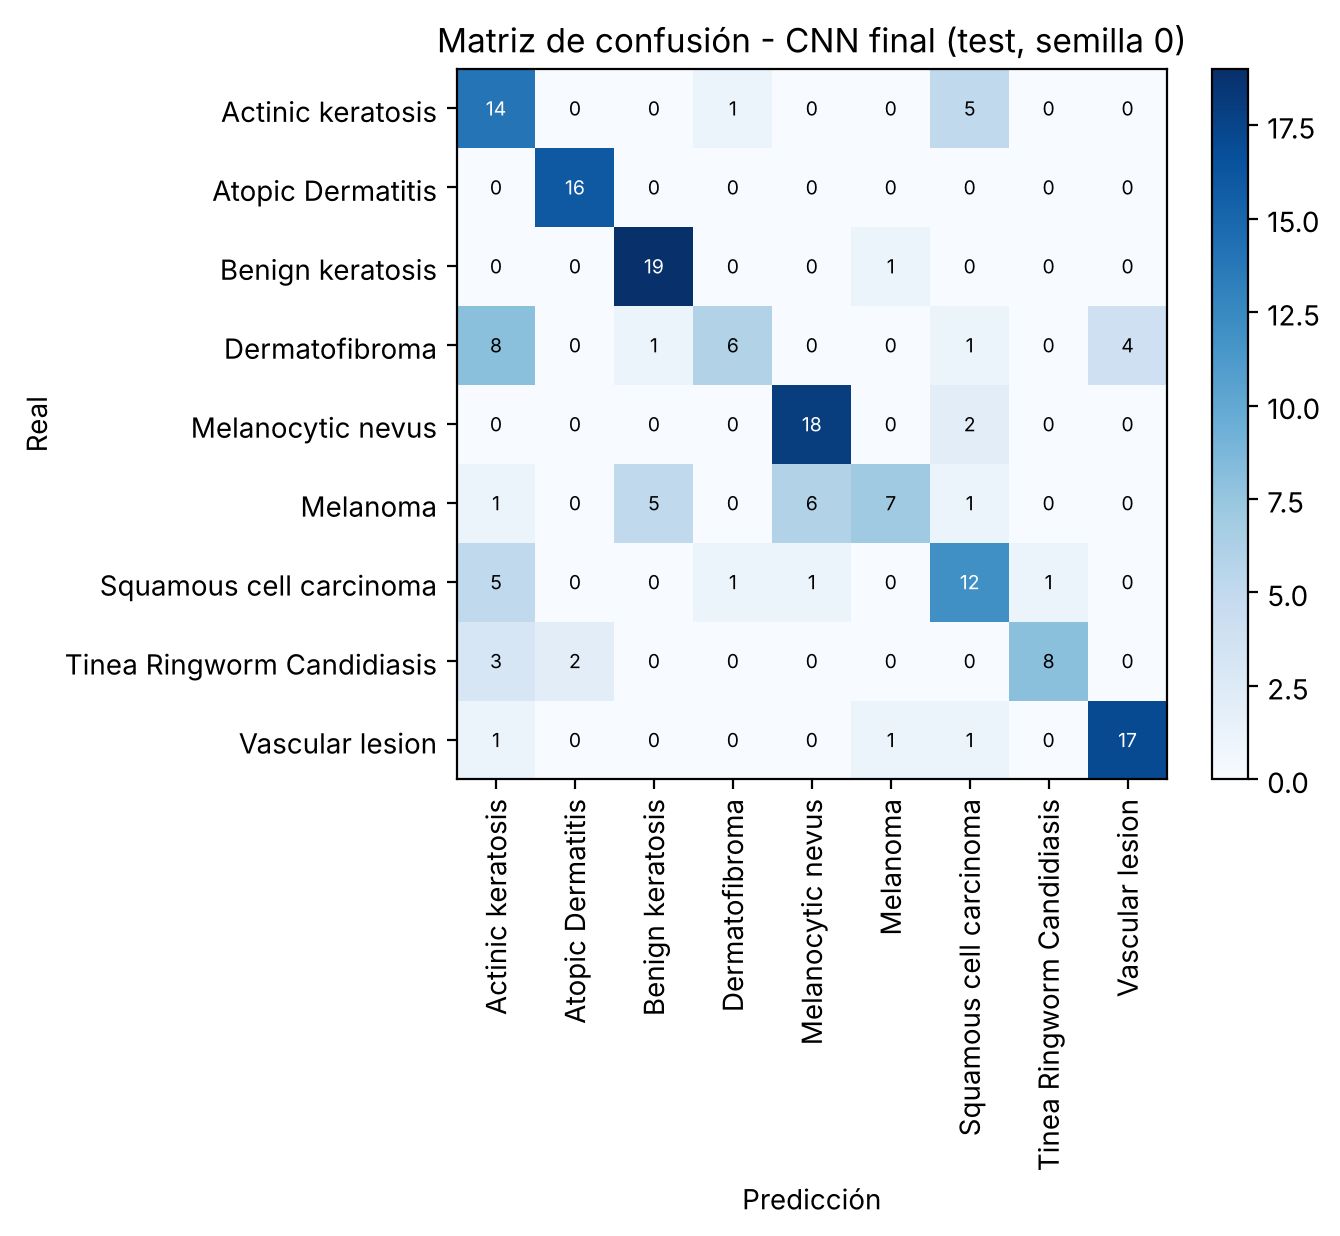

In [15]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

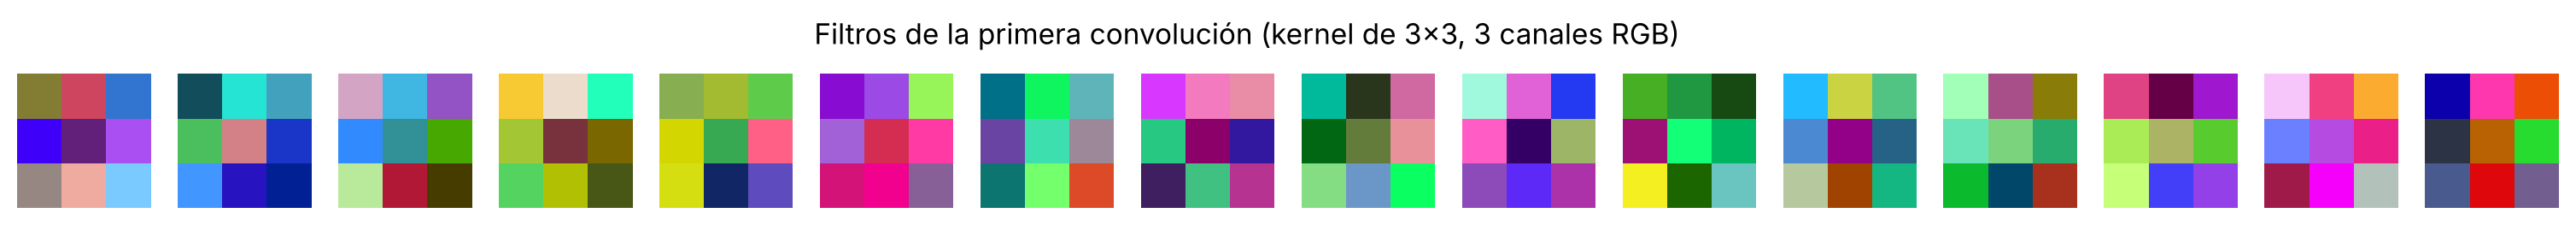

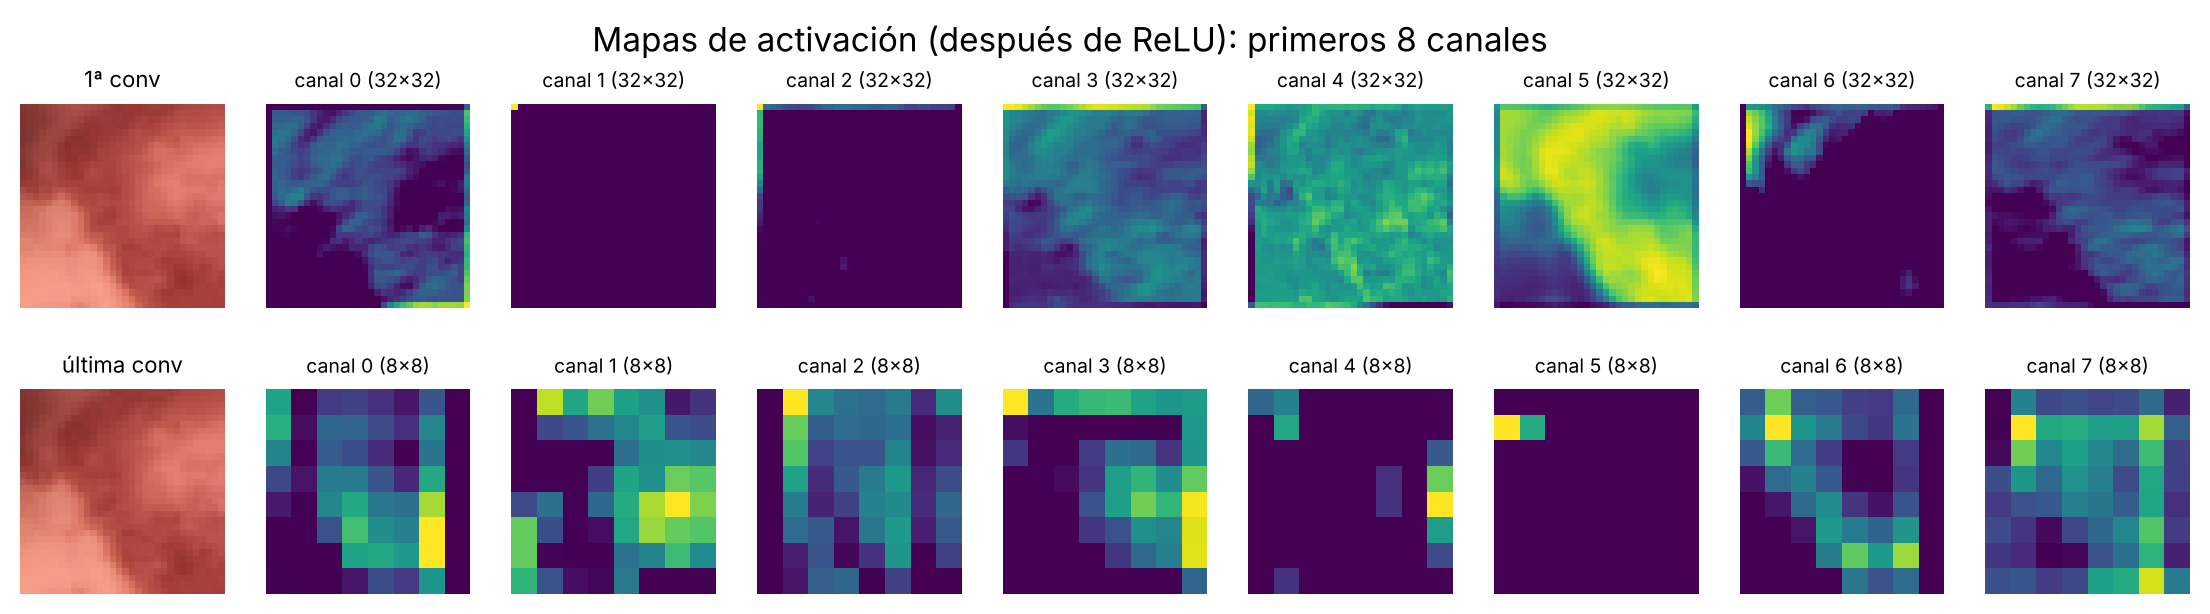

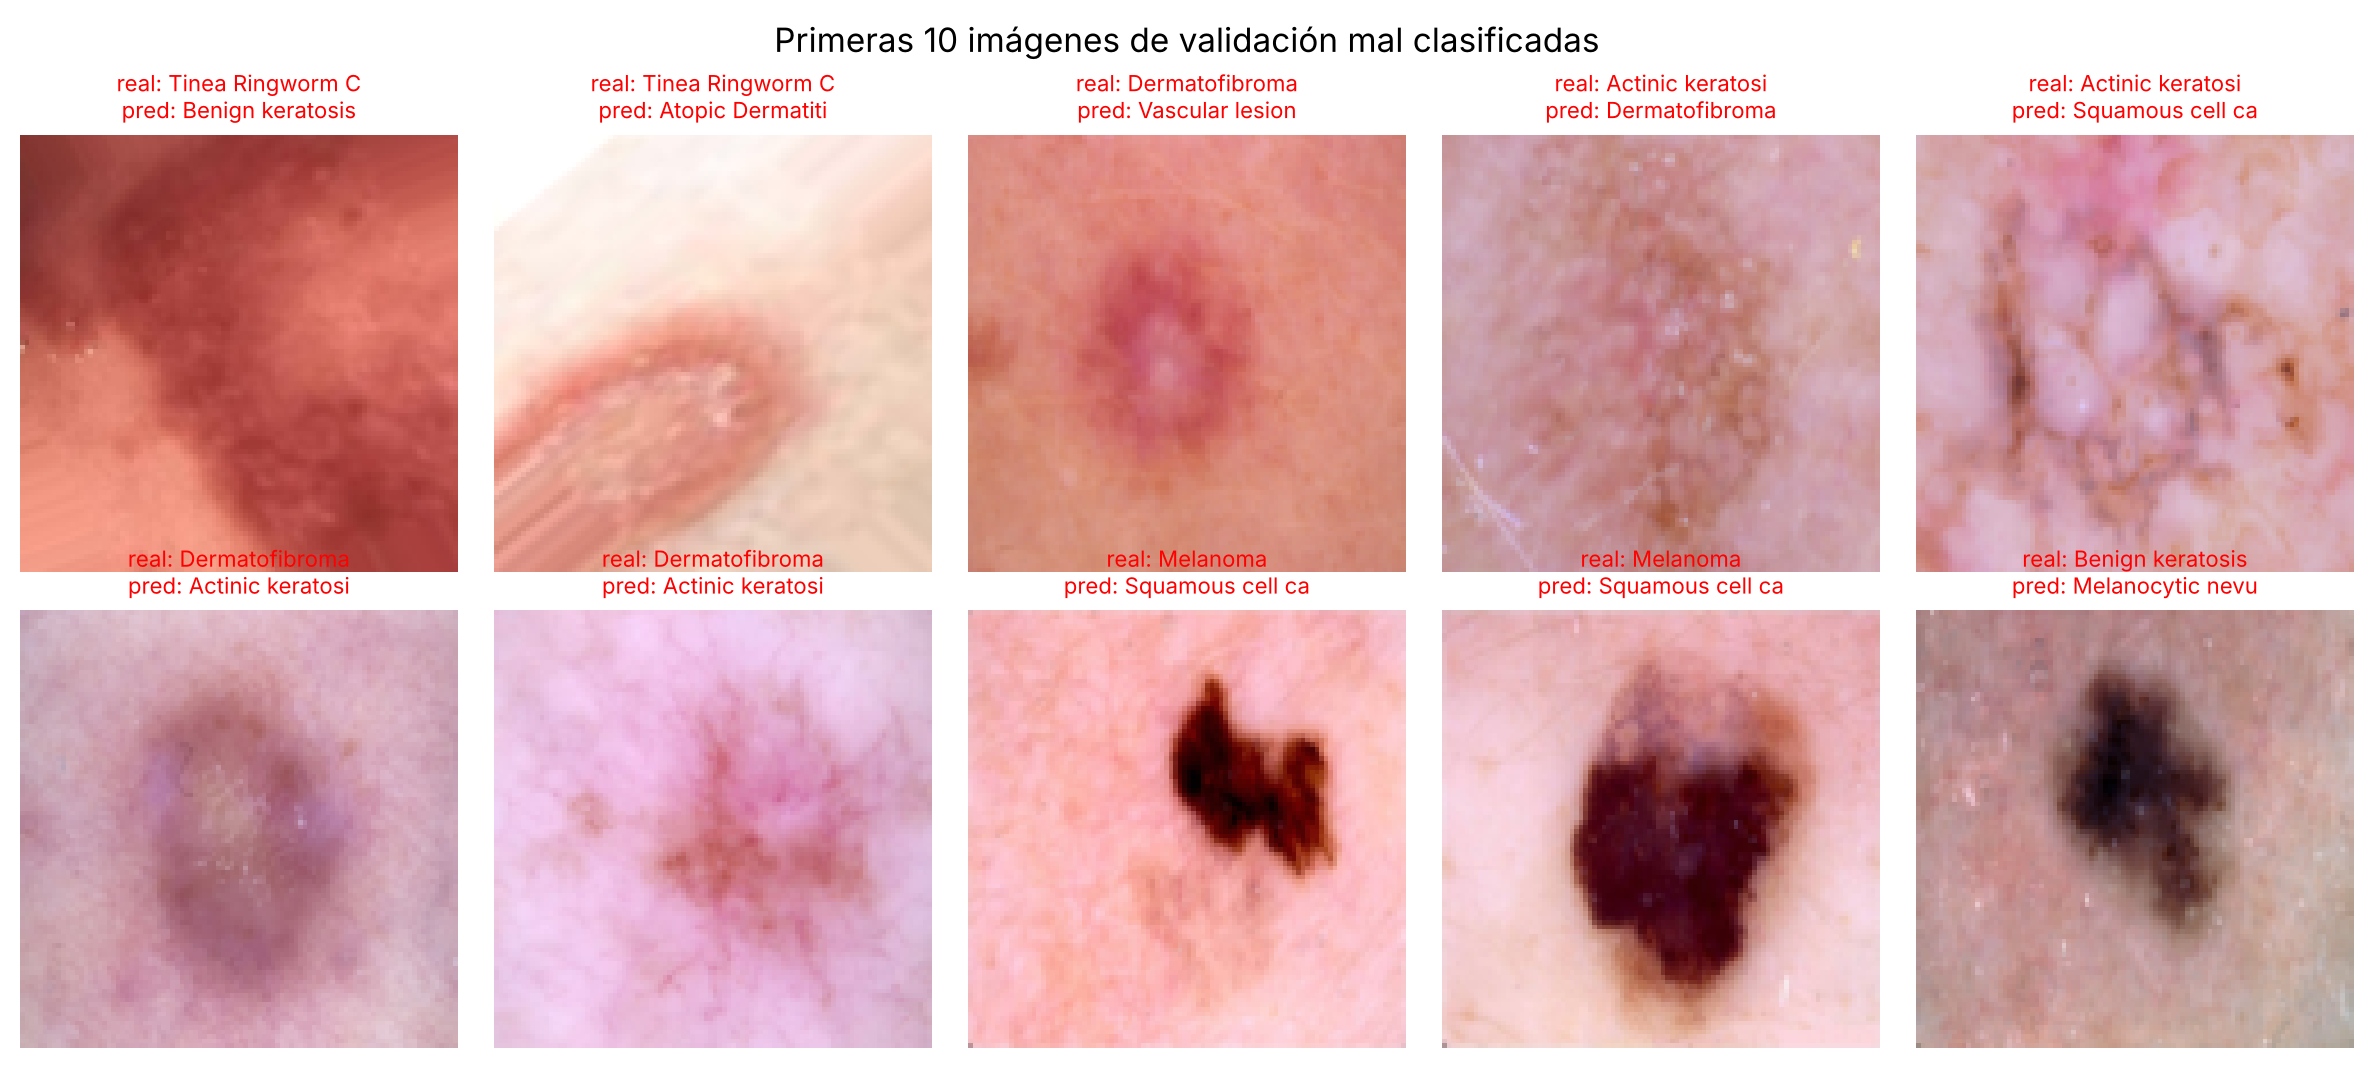

In [16]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?

---

**Respuestas**

**1.** La configuración final quedó en 32 px con la arquitectura base y sin augmentation, que en validación dio 0,661 ± 0,015. En test, con 5 semillas, llega a 0,673 ± 0,035 de accuracy y 0,671 ± 0,035 de macro-F1. Es coherente con la validación, la diferencia es de 1,2 puntos y el error estándar binomial del test es de ±3,6 puntos. Que el test no haya quedado por debajo, a pesar del sesgo optimista de elegir la mejor entre 9 arquitecturas y 4 augmentations, es en parte suerte, porque varias de esas variantes estaban empatadas dentro del ruido y el desvío entre semillas en test también es de 3,5 puntos.

**2.** La CNN le gana a la MLP por 16 puntos en test (0,673 ± 0,035 contra 0,514 ± 0,053), más de 3 veces el desvío entre semillas y más de 4 veces el error estándar del test, así que la diferencia es real. Se justifica sin dudas, porque además tiene 40 veces menos parámetros (156.057 contra 6.358.793) y hasta se entrena más rápido (3,9 s contra 5,5 s por entrenamiento), porque a 32 px cada época es barata.

**3.** En la matriz de confusión (semilla 0, 0,69 de accuracy) las clases que mejor anda son Atopic Dermatitis (16 de 16), Benign keratosis (19 de 20), Melanocytic nevus (18 de 20) y Vascular lesion (17 de 20). Las peores son Dermatofibroma (recall 0,30, 8 se predicen como Actinic keratosis y 4 como Vascular lesion) y Melanoma (recall 0,35, 6 se predicen como nevus y 5 como Benign keratosis), y después Squamous cell carcinoma y Actinic keratosis, que se confunden entre sí (5 en cada dirección). Tiene sentido clínico. Melanoma y nevus son las dos lesiones melanocíticas pigmentadas y distinguirlas es justamente el problema difícil de la dermatoscopía, la queratosis seborreica también puede ser pigmentada, la queratosis actínica es una lesión precursora del carcinoma escamoso y las dos son rosadas y escamosas, y el dermatofibroma también es rosado con una zona central más clara. Que Atopic Dermatitis salga perfecta probablemente tenga más que ver con que son fotos clínicas de baja resolución que con la lesión.

No es igual de grave cualquier error. Confundir un melanoma con un nevus es el peor caso, porque es un cáncer que no se deriva y se demora el diagnóstico, y lo mismo un carcinoma escamoso predicho como queratosis actínica. Al revés, un nevus predicho como melanoma es un falso positivo que termina en una biopsia de más. Por eso me parece más relevante el recall de las clases malignas, sobre todo el de melanoma, que acá es de 0,35 y sería inaceptable en la práctica, y como resumen general el F1 macro, que pesa igual a todas las clases. El accuracy esconde que el modelo se pierde el 65 % de los melanomas.

**4.** Los filtros de la primera convolución son de 3×3, así que como imagen son parches de colores. Se ven contrastes de color (verde contra magenta, azul contra naranja) que funcionan como detectores de diferencias de color y de bordes simples. En los mapas de activación de la primera capa (32×32) algunos canales responden a la zona más oscura de la lesión (el canal 5), otros a la textura de la piel (el 4), y varios casi no se activan salvo en el borde de la imagen, que se enciende por el padding con ceros (el borde queda como un contraste fuerte después de normalizar). En la última convolución los mapas son de 8×8, cada unidad ve 18 px de una imagen de 32 (más de la mitad del lado), las activaciones están más concentradas y ya no se parecen a la imagen, marcan zonas más que bordes. En las imágenes mal clasificadas se repiten las lesiones rosadas o rojizas de poco contraste con la piel (dermatofibromas, queratosis actínicas, carcinomas), los melanomas oscuros predichos como carcinoma escamoso, y dos Tinea con aspecto de foto clínica o encuadre parcial. A 32 px se pierde buena parte de las estructuras finas que distinguen esos casos.

**5.** El sesgo más fuerte es el de adquisición. Varias clases vienen cada una de una fuente distinta (Atopic Dermatitis todas de 294×222 y fotos clínicas, Tinea fotos clínicas, Benign keratosis con reflejos de flash, nevus y melanoma con el viñeteado del dermatoscopio), así que el modelo puede separar clases por la cámara, el fondo o el nivel de detalle, y los números quedan inflados respecto de lo que daría con imágenes de otra fuente. Las diferencias de color por clase también vienen en parte de eso. Se sacaron los duplicados exactos, pero puede haber fotos distintas de una misma lesión o de un mismo paciente en train y test, y el hash perceptual solo detecta imágenes casi idénticas. El dataset es chico (506 de train, 169 de validación y 169 de test, con un error estándar de 3,6 puntos), hay una sola partición, 3 semillas en las comparaciones y 5 en test, y el balance entre clases es artificial (en la realidad los nevus son muchísimo más frecuentes que los melanomas, así que la precisión sería otra). Con más tiempo haría validación cruzada estratificada repetida para usar todas las imágenes y medir la variación por el split, augmentation en línea, recortaría la lesión y normalizaría la adquisición (misma resolución, sin bordes ni viñeteado, corrección de color) para ver si el accuracy se sostiene sin las pistas del equipo, miraría con mapas de saliencia en qué zonas se apoya la red, probaría transfer learning con una red preentrenada y usaría más imágenes del ISIC completo.

## Declaración de uso de IA
Completen (obligatorio): ¿usaron herramientas de IA? ¿Cuáles, para qué parte (código, redacción del análisis, ideas) y qué modificaron o verificaron por su cuenta? Si no usaron, aclaren que no.

Usé Claude para generar el README, el archivo requirements.txt y los códigos necesarios para generar las figuras. El código principal del notebook ya estaba resuelto por la cátedra y no lo modifiqué. Por mi parte, realicé el análisis de los resultados, revisando las tablas y los gráficos obtenidos, verificando los cálculos y profundizando los resultados que no me cerraban, con Claude y ChatGPT. Una vez finalizado esto, usé Claude y ChatGPT para mejorar la redacción del análisis y verificar que no se me hubiera pasado nada.